In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/SCENIC_Systems_Biology/transfer"
)

print("Folder exists:", PROJECT_DIR.exists())
print("Files:", list(PROJECT_DIR.iterdir()))


Folder exists: True
Files: [PosixPath('/content/drive/MyDrive/SCENIC_Systems_Biology/transfer/pbmc3k_expression.csv'), PosixPath('/content/drive/MyDrive/SCENIC_Systems_Biology/transfer/adjacencies.csv')]


In [3]:
!pip install pyscenic==0.12.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 10.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 13.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 76.0 MB/s  0:00:00
  Created wheel for interlap: filename=interlap-0.2.7-py3-none-any.whl size=6361 sha256=28dd5a7e49e69e4adbee7d3b75b9d0aeb198030e1375b72323e65ea30c261137
  Stored in directory: /root/.cache/pip/wheels/b0/e0/ab/9d42c16236cccc3c88434fdc47498611d77bad8d07b59e40b3
  Created wheel for loompy: filename=loompy-3.0.8-py3-none-any.whl size=54099 sha256=3ff3abe234bebc9bdce4dc00d0a6

In [4]:
from pathlib import Path
import subprocess
import os
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/SCENIC_Systems_Biology/transfer"
)

ADJACENCY_FILE = PROJECT_DIR / "adjacencies.csv"
EXPRESSION_FILE = PROJECT_DIR / "pbmc3k_expression.csv"

RESOURCE_DIR = Path("/content/scenic_resources")
RESULT_DIR = Path(
    "/content/drive/MyDrive/SCENIC_Systems_Biology/results"
)

RESOURCE_DIR.mkdir(parents=True, exist_ok=True)
(RESULT_DIR / "regulons").mkdir(parents=True, exist_ok=True)

print("Adjacency file exists:", ADJACENCY_FILE.exists())
print("Expression file exists:", EXPRESSION_FILE.exists())

Adjacency file exists: True
Expression file exists: True


In [5]:
!free -h

               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.3Gi       8.7Gi       3.3Mi       3.0Gi        11Gi
Swap:             0B          0B          0B


In [6]:
RANKING_DB = RESOURCE_DIR / (
    "hg19-tss-centered-10kb-10species."
    "mc9nr.genes_vs_motifs.rankings.feather"
)

RANKING_URL = (
    "https://resources.aertslab.org/cistarget/databases/"
    "homo_sapiens/hg19/refseq_r45/mc9nr/gene_based/"
    "hg19-tss-centered-10kb-10species."
    "mc9nr.genes_vs_motifs.rankings.feather"
)

if not RANKING_DB.exists():
    !wget -c -O "$RANKING_DB" "$RANKING_URL"

print("Ranking database exists:", RANKING_DB.exists())

if RANKING_DB.exists():
    print("Size (MB):", round(RANKING_DB.stat().st_size / (1024**2), 2))

--2026-11-10 05:00:22--  https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg19/refseq_r45/mc9nr/gene_based/hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings.feather
Resolving resources.aertslab.org (resources.aertslab.org)... 134.58.50.9
Connecting to resources.aertslab.org (resources.aertslab.org)|134.58.50.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1004905162 (958M)
Saving to: ‘/content/scenic_resources/hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings.feather’

/content/scenic_res 100%[===================>] 958.35M  14.7MB/s    in 67s     

2026-11-10 05:01:30 (14.3 MB/s) - ‘/content/scenic_resources/hg19-tss-centered-10kb-10species.mc9nr.genes_vs_motifs.rankings.feather’ saved [1004905162/1004905162]

Ranking database exists: True
Size (MB): 958.35


In [7]:
ANNOTATION_FILE = RESOURCE_DIR / "motif_annotations.tbl"

ANNOTATION_URL = (
    "https://resources.aertslab.org/cistarget/motif2tf/"
    "motifs-v9-nr.hgnc-m0.001-o0.0.tbl"
)

if not ANNOTATION_FILE.exists():
    !wget -c -O "$ANNOTATION_FILE" "$ANNOTATION_URL"

print("Annotation file exists:", ANNOTATION_FILE.exists())

--2026-11-10 05:02:50--  https://resources.aertslab.org/cistarget/motif2tf/motifs-v9-nr.hgnc-m0.001-o0.0.tbl
Resolving resources.aertslab.org (resources.aertslab.org)... 134.58.50.9
Connecting to resources.aertslab.org (resources.aertslab.org)|134.58.50.9|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 103568514 (99M)
Saving to: ‘/content/scenic_resources/motif_annotations.tbl’

/content/scenic_res 100%[===================>]  98.77M  9.65MB/s    in 12s     

2026-11-10 05:03:03 (8.58 MB/s) - ‘/content/scenic_resources/motif_annotations.tbl’ saved [103568514/103568514]

Annotation file exists: True


In [8]:
import psutil

print("Available RAM:",
      round(psutil.virtual_memory().available / (1024**3), 2), "GB")

print("\nRanking database exists:", RANKING_DB.exists())

if RANKING_DB.exists():
    print("Ranking database size:",
          round(RANKING_DB.stat().st_size / (1024**2), 2), "MB")

print("\nAnnotation file exists:", ANNOTATION_FILE.exists())
print("Adjacency file exists:", ADJACENCY_FILE.exists())
print("Expression file exists:", EXPRESSION_FILE.exists())

Available RAM: 11.41 GB

Ranking database exists: True
Ranking database size: 958.35 MB

Annotation file exists: True
Adjacency file exists: True
Expression file exists: True


In [9]:
import sys
import shutil

print("Python:", sys.executable)
print("pySCENIC:", shutil.which("pyscenic"))

!pyscenic ctx --help

Python: /usr/bin/python3
pySCENIC: /usr/local/bin/pyscenic
/usr/local/lib/python3.13/dist-packages/ctxcore/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/usr/local/lib/python3.13/dist-packages/pyscenic/transform.py:42: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  ("Enrichment", COLUMN_NAME_ANNOTATION): np.object,
Traceback (most recent call last):
  File "/usr/local/bin/pyscenic", line 3, in <module>
    from pyscenic.cli.pyscenic import main
  File "/usr/local/lib/python3.13/dist-packages/pyscenic/cli/pyscenic.py", line 26, in <module>
    from pyscenic.prune import _prepare_client, find_features, prune2df
  File "/usr/local/lib/python3.13/dist-packages/pyscenic/p

In [10]:
from pathlib import Path
import pyscenic

transform_file = (
    Path(pyscenic.__file__).parent / "transform.py"
)

source = transform_file.read_text()

source = source.replace("np.object", "object")

transform_file.write_text(source)

print("Compatibility patch applied!")

Compatibility patch applied!


In [11]:
!pyscenic ctx --help

/usr/local/lib/python3.13/dist-packages/ctxcore/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
usage: pyscenic ctx [-h] [-o OUTPUT] [-n] [--chunk_size CHUNK_SIZE]
                    [--mode {custom_multiprocessing,dask_multiprocessing,dask_cluster}]
                    [-a] [-t] [--rank_threshold RANK_THRESHOLD]
                    [--auc_threshold AUC_THRESHOLD]
                    [--nes_threshold NES_THRESHOLD]
                    [--min_orthologous_identity MIN_ORTHOLOGOUS_IDENTITY]
                    [--max_similarity_fdr MAX_SIMILARITY_FDR]
                    --annotations_fname ANNOTATIONS_FNAME
                    [--num_workers NUM_WORKERS]
                    [--client_or_address CLIENT_OR_ADDRESS]
  

In [12]:
import subprocess

REGULONS_FILE = RESULT_DIR / "regulons" / "regulons.csv"

command = [
    "pyscenic",
    "ctx",
    str(ADJACENCY_FILE),
    str(RANKING_DB),
    "--annotations_fname", str(ANNOTATION_FILE),
    "--expression_mtx_fname", str(EXPRESSION_FILE),
    "--mode", "custom_multiprocessing",
    "--num_workers", "1",
    "--nes_threshold", "3.0",
    "--output", str(REGULONS_FILE)
]

with open(RESULT_DIR / "regulons" / "ctx_log.txt", "w") as log:
    result = subprocess.run(
        command,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True
    )

print("Return code:", result.returncode)
print("Regulon file created:", REGULONS_FILE.exists())

if result.returncode != 0:
    print((RESULT_DIR / "regulons" / "ctx_log.txt").read_text()[-5000:])

Return code: 0
Regulon file created: True


In [14]:
import pandas as pd

regulons_df = pd.read_csv(REGULONS_FILE)

print("Number of motif-enrichment results:", len(regulons_df))
print("\nColumns:")
print(regulons_df.columns.tolist())

display(regulons_df.head(10))

Number of motif-enrichment results: 7294

Columns:
['Unnamed: 0', 'Unnamed: 1', 'Enrichment', 'Enrichment.1', 'Enrichment.2', 'Enrichment.3', 'Enrichment.4', 'Enrichment.5', 'Enrichment.6', 'Enrichment.7']


,Unnamed: 0,Unnamed: 1,Enrichment,Enrichment.1,Enrichment.2,Enrichment.3,Enrichment.4,Enrichment.5,Enrichment.6,Enrichment.7
0,NaN,NaN,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
1,TF,MotifID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ARID3A,jaspar__MA0151.1,0.08054101353288173,3.001959109240464,0.0,0.809444,gene is orthologous to ENSMUSG00000019564 in M...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('PRRC1', np.float64(0.6276904979674736)), ('...",1321
3,ARNTL,hocomoco__MITF_MOUSE.H11MO.0.A,0.06858729802513465,3.38591882201101,0.000955,0.984026,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",4198
4,ARNTL,scertf__spivak.TYE7,0.06814547800718133,3.3478651131219057,0.000854,1.0,motif similar to cisbp__M5290 ('ARNTL2[gene ID...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",640
5,ARNTL,transfac_pro__M08978,0.0682997643626571,3.3611537098768314,0.000633,1.0,motif similar to taipale_cyt_meth__ARNTL_RTCAC...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",3886
6,ARNTL,transfac_pro__M09495,0.064456631508079,3.0301468452541394,0.000604,0.984026,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",2315
7,ARNTL,taipale__TFE3_DBD_NNCACGTGNN,0.06962522441651706,3.475314836544146,0.000565,1.0,motif similar to cisbp__M5290 ('ARNTL2[gene ID...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",4197
8,ARNTL,cisbp__M4553,0.06468806104129264,3.050079740386528,0.000554,0.984026,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('ARNTL', np.float64(1.0)), ('IGSF9B', np.flo...",451
9,ARNTL,cisbp__M5930,0.06968834156193895,3.4807510806711606,0.000504,1.0,motif similar to taipale__ARNTL_DBD_GTCACGTGAC...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('S1PR4', np.float64(0.6231231143596108)), ('...",549


In [15]:
print("Unique TFs:", regulons_df["TF"].nunique())

if "NES" in regulons_df.columns:
    print("Mean NES:", regulons_df["NES"].mean())
    print("Maximum NES:", regulons_df["NES"].max())

print("\nTop TFs by motif enrichment:")
display(
    regulons_df.sort_values(
        "NES", ascending=False
    ).head(10)
)

KeyError: 'TF'

In [16]:
print("Columns:", regulons_df.columns.tolist())
print("Shape:", regulons_df.shape)

display(regulons_df.head(3))

Columns: ['Unnamed: 0', 'Unnamed: 1', 'Enrichment', 'Enrichment.1', 'Enrichment.2', 'Enrichment.3', 'Enrichment.4', 'Enrichment.5', 'Enrichment.6', 'Enrichment.7']
Shape: (7294, 10)


,Unnamed: 0,Unnamed: 1,Enrichment,Enrichment.1,Enrichment.2,Enrichment.3,Enrichment.4,Enrichment.5,Enrichment.6,Enrichment.7
0,NaN,NaN,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
1,TF,MotifID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ARID3A,jaspar__MA0151.1,0.08054101353288173,3.001959109240464,0.0,0.809444,gene is orthologous to ENSMUSG00000019564 in M...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('PRRC1', np.float64(0.6276904979674736)), ('...",1321


In [17]:
print(regulons_df.dtypes)
print("\nFirst row:")
print(regulons_df.iloc[0].to_dict())

Unnamed: 0      object
Unnamed: 1      object
Enrichment      object
Enrichment.1    object
Enrichment.2    object
Enrichment.3    object
Enrichment.4    object
Enrichment.5    object
Enrichment.6    object
Enrichment.7    object
dtype: object

First row:
{'Unnamed: 0': nan, 'Unnamed: 1': nan, 'Enrichment': 'AUC', 'Enrichment.1': 'NES', 'Enrichment.2': 'MotifSimilarityQvalue', 'Enrichment.3': 'OrthologousIdentity', 'Enrichment.4': 'Annotation', 'Enrichment.5': 'Context', 'Enrichment.6': 'TargetGenes', 'Enrichment.7': 'RankAtMax'}


In [18]:
regulons_df = pd.read_csv(
    REGULONS_FILE,
    header=[0, 1]
)

print("Shape:", regulons_df.shape)
print("\nColumns:")
print(regulons_df.columns.tolist())

display(regulons_df.head(5))

Shape: (7293, 10)

Columns:
[('Unnamed: 0_level_0', 'Unnamed: 0_level_1'), ('Unnamed: 1_level_0', 'Unnamed: 1_level_1'), ('Enrichment', 'AUC'), ('Enrichment', 'NES'), ('Enrichment', 'MotifSimilarityQvalue'), ('Enrichment', 'OrthologousIdentity'), ('Enrichment', 'Annotation'), ('Enrichment', 'Context'), ('Enrichment', 'TargetGenes'), ('Enrichment', 'RankAtMax')]


Unnamed: 0_level_0              Unnamed: 1_level_0 Enrichment            \
  Unnamed: 0_level_1              Unnamed: 1_level_1        AUC       NES   
0                 TF                         MotifID        NaN       NaN   
1             ARID3A                jaspar__MA0151.1   0.080541  3.001959   
2              ARNTL  hocomoco__MITF_MOUSE.H11MO.0.A   0.068587  3.385919   
3              ARNTL             scertf__spivak.TYE7   0.068145  3.347865   
4              ARNTL            transfac_pro__M08978   0.068300  3.361154   

                                             \
  MotifSimilarityQvalue OrthologousIdentity   
0                   NaN                 NaN   
1              0.000000            0.809444   
2              0.000955            0.984026   
3              0.000854            1.000000   
4              0.000633            1.000000   

                                                      \
                                          Annotation   
0                                                NaN   
1  gene is orthologous to ENSMUSG00000019564 in M...   
2  motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...   
3  motif similar to cisbp__M5290 ('ARNTL2[gene ID...   
4  motif similar to taipale_cyt_meth__ARNTL_RTCAC...   

                                                      \
                                             Context   
0                                                NaN   
1  frozenset({'activating', 'weight>75.0%', 'hg19...   
2  frozenset({'activating', 'weight>75.0%', 'hg19...   
3  frozenset({'activating', 'weight>75.0%', 'hg19...   
4  frozenset({'activating', 'weight>75.0%', 'hg19...   

                                                                
                                         TargetGenes RankAtMax  
0                                                NaN       NaN  
1  [('PRRC1', np.float64(0.6276904979674736)), ('...    1321.0  
2  [('LYPLA2', np.float64(0.835578751582191)), ('...    4198.0  
3  [('LYPLA2', np.float64(0.835578751582191)), ('...     640.0  
4  [('LYPLA2', np.float64(0.835578751582191)), ('...    3886.0

In [19]:
print("Available column levels:")

for column in regulons_df.columns:
    print(column)

Available column levels:
('Unnamed: 0_level_0', 'Unnamed: 0_level_1')
('Unnamed: 1_level_0', 'Unnamed: 1_level_1')
('Enrichment', 'AUC')
('Enrichment', 'NES')
('Enrichment', 'MotifSimilarityQvalue')
('Enrichment', 'OrthologousIdentity')
('Enrichment', 'Annotation')
('Enrichment', 'Context')
('Enrichment', 'TargetGenes')
('Enrichment', 'RankAtMax')


In [20]:
# Flatten the two-level column names
regulons_flat = regulons_df.copy()

regulons_flat.columns = [
    col[1] if col[0] == "Enrichment" else col[1]
    for col in regulons_flat.columns
]

# Remove the first two rows containing header information
regulons_flat = regulons_flat.iloc[2:].reset_index(drop=True)

# Rename the first two columns
regulons_flat = regulons_flat.rename(columns={
    "Unnamed: 0_level_1": "TF",
    "Unnamed: 1_level_1": "MotifID"
})

# Convert numerical columns
regulons_flat["NES"] = pd.to_numeric(
    regulons_flat["NES"], errors="coerce"
)

print("Total motif results:", len(regulons_flat))
print("Unique TFs:", regulons_flat["TF"].nunique())

display(regulons_flat.head())

Total motif results: 7291
Unique TFs: 252


,TF,MotifID,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
0,ARNTL,hocomoco__MITF_MOUSE.H11MO.0.A,0.068587,3.385919,0.000955,0.984026,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",4198.0
1,ARNTL,scertf__spivak.TYE7,0.068145,3.347865,0.000854,1.000000,motif similar to cisbp__M5290 ('ARNTL2[gene ID...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",640.0
2,ARNTL,transfac_pro__M08978,0.068300,3.361154,0.000633,1.000000,motif similar to taipale_cyt_meth__ARNTL_RTCAC...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",3886.0
3,ARNTL,transfac_pro__M09495,0.064457,3.030147,0.000604,0.984026,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",2315.0
4,ARNTL,taipale__TFE3_DBD_NNCACGTGNN,0.069625,3.475315,0.000565,1.000000,motif similar to cisbp__M5290 ('ARNTL2[gene ID...,"frozenset({'activating', 'weight>75.0%', 'hg19...","[('LYPLA2', np.float64(0.835578751582191)), ('...",4197.0


In [21]:
significant = regulons_flat[
    regulons_flat["NES"] >= 3.0
].copy()

print("Significant motif results:", len(significant))
print("Unique TFs:", significant["TF"].nunique())

display(
    significant.sort_values("NES", ascending=False).head(10)
)

Significant motif results: 7291
Unique TFs: 252


,TF,MotifID,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
3772,SPI1,taipale_cyt_meth__SPIB_RAWWGRGGAAGTN_FL_meth,0.172462,11.243038,0.000003,1.0,gene is annotated for similar motif transfac_p...,"frozenset({'activating', 'top50', 'hg19-tss-ce...","[('GABARAP', np.float64(5.335175019701239)), (...",565.0
3769,SPI1,taipale_cyt_meth__SPIB_RWWGRGGAAGTN_eDBD_meth,0.158575,10.249898,0.000009,1.0,gene is annotated for similar motif transfac_p...,"frozenset({'activating', 'top50', 'hg19-tss-ce...","[('FTL', np.float64(5.0673611945549135)), ('SL...",528.0
1398,EP300,taipale_cyt_meth__ELF1_NACCCGGAAGTN_eDBD,0.139284,7.521205,0.000767,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'weight>90.0%', 'hg19...","[('HMG20A', np.float64(1.1284452143200607)), (...",2637.0
1400,EP300,taipale_cyt_meth__ELF1_NACCCGGAAGTN_FL,0.136154,7.335039,0.000767,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'weight>90.0%', 'hg19...","[('HMG20A', np.float64(1.1284452143200607)), (...",123.0
4066,E2F4,dbcorrdb__SP2__ENCSR000BQG_1__m1,0.131176,7.312226,0.000297,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'top5perTarget', 'hg1...","[('TXK', np.float64(1.3148133301334122)), ('IS...",2079.0
3768,SPI1,taipale_cyt_meth__SPIB_RWWGSGGAAGTN_eDBD_repr,0.112391,6.946857,0.000040,1.0,gene is annotated for similar motif transfac_p...,"frozenset({'activating', 'top50', 'hg19-tss-ce...","[('FOSB', np.float64(4.948134840075921)), ('LY...",469.0
2871,EP300,taipale_cyt_meth__ELF1_NACCCGGAAGTN_eDBD,0.114522,6.890015,0.000767,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'top50', 'hg19-tss-ce...","[('HMG20A', np.float64(1.1284452143200607)), (...",123.0
4111,E2F4,dbcorrdb__E2F4__ENCSR000DYY_1__m2,0.123722,6.864850,0.000000,1.0,gene is directly annotated,"frozenset({'activating', 'top5perTarget', 'hg1...","[('HSPA5', np.float64(1.282302564382242)), ('P...",247.0
4101,E2F4,cisbp__M6372,0.123683,6.862507,0.000000,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'top5perTarget', 'hg1...","[('LAS1L', np.float64(3.053535874021699)), ('P...",421.0
4084,E2F4,transfac_pro__M04683,0.123605,6.857823,0.000000,1.0,gene is annotated for similar motif dbcorrdb__...,"frozenset({'activating', 'top5perTarget', 'hg1...","[('ISG20L2', np.float64(0.934262684795584)), (...",2041.0


In [22]:
CLEAN_REGULONS = RESULT_DIR / "regulons" / "regulons_cleaned.csv"

significant.to_csv(CLEAN_REGULONS, index=False)

print("Saved:", CLEAN_REGULONS)

Saved: /content/drive/MyDrive/SCENIC_Systems_Biology/results/regulons/regulons_cleaned.csv


In [23]:
print("TargetGenes column:")
print(regulons_df[("Enrichment", "TargetGenes")].iloc[1])

print("\nAUCell command options:")

import subprocess

result = subprocess.run(
    ["pyscenic", "aucell", "--help"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr[-1500:])

TargetGenes column:
[('PRRC1', np.float64(0.6276904979674736)), ('UCK2', np.float64(0.4492124335250651)), ('NPHP4', np.float64(0.5430952884890397)), ('EPHX1', np.float64(0.640503445093953)), ('MAFB', np.float64(1.7345809740829763)), ('TLE3', np.float64(0.860672970322775)), ('NDST2', np.float64(4.352498060195746)), ('FGFRL1', np.float64(1.1602152031556312)), ('DUSP19', np.float64(1.3793165683758253)), ('KRT7', np.float64(0.9659682928862136)), ('TPM4', np.float64(0.71345309869756)), ('FADS2', np.float64(1.1202148227024913)), ('NKD1', np.float64(0.4898886025385613)), ('NAV1', np.float64(0.5523320090168291)), ('SLC27A4', np.float64(1.4983853088821817)), ('PDE4C', np.float64(1.643803852535243)), ('FAM78A', np.float64(0.4819740989419373)), ('XAF1', np.float64(1.2777683752113465)), ('DLGAP3', np.float64(0.6509753968638143)), ('ARID3A', np.float64(1.0)), ('WDR47', np.float64(0.7403403365491414)), ('RGL2', np.float64(0.5426958829835209)), ('LSM12', np.float64(0.9244627032259134)), ('RYBP', np.f

In [24]:
# Inspect one target-gene entry
target_col = ("Enrichment", "TargetGenes")

print("Example target genes:")
print(regulons_df[target_col].iloc[1])

print("\nData type:")
print(type(regulons_df[target_col].iloc[1]))

Example target genes:
[('PRRC1', np.float64(0.6276904979674736)), ('UCK2', np.float64(0.4492124335250651)), ('NPHP4', np.float64(0.5430952884890397)), ('EPHX1', np.float64(0.640503445093953)), ('MAFB', np.float64(1.7345809740829763)), ('TLE3', np.float64(0.860672970322775)), ('NDST2', np.float64(4.352498060195746)), ('FGFRL1', np.float64(1.1602152031556312)), ('DUSP19', np.float64(1.3793165683758253)), ('KRT7', np.float64(0.9659682928862136)), ('TPM4', np.float64(0.71345309869756)), ('FADS2', np.float64(1.1202148227024913)), ('NKD1', np.float64(0.4898886025385613)), ('NAV1', np.float64(0.5523320090168291)), ('SLC27A4', np.float64(1.4983853088821817)), ('PDE4C', np.float64(1.643803852535243)), ('FAM78A', np.float64(0.4819740989419373)), ('XAF1', np.float64(1.2777683752113465)), ('DLGAP3', np.float64(0.6509753968638143)), ('ARID3A', np.float64(1.0)), ('WDR47', np.float64(0.7403403365491414)), ('RGL2', np.float64(0.5426958829835209)), ('LSM12', np.float64(0.9244627032259134)), ('RYBP', np

In [26]:
import re
from collections import defaultdict
import pandas as pd

# Extract columns by position to avoid MultiIndex ambiguity
data = pd.DataFrame({
    "TF": regulons_df.iloc[1:, 0].astype(str).to_numpy(),
    "NES": pd.to_numeric(
        regulons_df.iloc[1:][("Enrichment", "NES")],
        errors="coerce"
    ).to_numpy(),
    "TargetGenes": regulons_df.iloc[1:][
        ("Enrichment", "TargetGenes")
    ].to_numpy()
})

# Keep motif results with NES >= 3
data = data[data["NES"] >= 3.0].copy()

# Extract gene symbols from target-gene strings
def extract_genes(value):
    if not isinstance(value, str):
        return []

    return re.findall(
        r"\('([^']+)',\s*np\.float64\(",
        value
    )

regulon_targets = defaultdict(set)

for tf, targets in zip(data["TF"], data["TargetGenes"]):
    genes = extract_genes(targets)

    if tf and tf != "nan":
        regulon_targets[tf].update(genes)

regulon_targets = {
    tf: sorted(genes)
    for tf, genes in regulon_targets.items()
    if genes
}

print("Number of regulons:", len(regulon_targets))
print(
    "Total TF-target relationships:",
    sum(len(genes) for genes in regulon_targets.values())
)

for tf, genes in list(regulon_targets.items())[:5]:
    print(tf, ":", len(genes), "targets")

Number of regulons: 252
Total TF-target relationships: 30661
ARID3A : 37 targets
ARNTL : 93 targets
ATF6 : 101 targets
BHLHE40 : 231 targets
BRCA1 : 208 targets


In [27]:
GMT_FILE = RESULT_DIR / "regulons" / "pbmc3k_regulons.gmt"

with open(GMT_FILE, "w") as f:
    for tf, genes in regulon_targets.items():
        f.write(
            tf + "\tSCENIC_motif_supported_targets\t"
            + "\t".join(genes) + "\n"
        )

print("GMT file saved:", GMT_FILE)
print("File exists:", GMT_FILE.exists())

GMT file saved: /content/drive/MyDrive/SCENIC_Systems_Biology/results/regulons/pbmc3k_regulons.gmt
File exists: True


In [28]:
import subprocess

AUCELL_FILE = RESULT_DIR / "regulons" / "pbmc3k_aucell.csv"

command = [
    "pyscenic",
    "aucell",
    str(EXPRESSION_FILE),
    str(GMT_FILE),
    "--output", str(AUCELL_FILE),
    "--num_workers", "1",
    "--seed", "42"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("AUCell file created:", AUCELL_FILE.exists())

if result.returncode != 0:
    print(result.stderr[-5000:])

Return code: 0
AUCell file created: True


In [29]:
auc_matrix = pd.read_csv(AUCELL_FILE, index_col=0)

print("AUCell matrix shape:", auc_matrix.shape)
print("Number of cells:", auc_matrix.shape[0])
print("Number of regulons:", auc_matrix.shape[1])

display(auc_matrix.iloc[:5, :5])

AUCell matrix shape: (2689, 252)
Number of cells: 2689
Number of regulons: 252


,AHR,ARID3A,ARNT,ARNTL,ATF1
Cell,,,,,
AAACATACAACCAC-1,0.000712,0.000000,0.000000,0.054740,0.034407
AAACATTGAGCTAC-1,0.021527,0.000000,0.000000,0.006644,0.011469
AAACATTGATCAGC-1,0.001464,0.000000,0.022217,0.010406,0.068814
AAACCGTGCTTCCG-1,0.012386,0.146255,0.000000,0.008753,0.000000
AAACCGTGTATGCG-1,0.050018,0.002849,0.000000,0.014547,0.037213


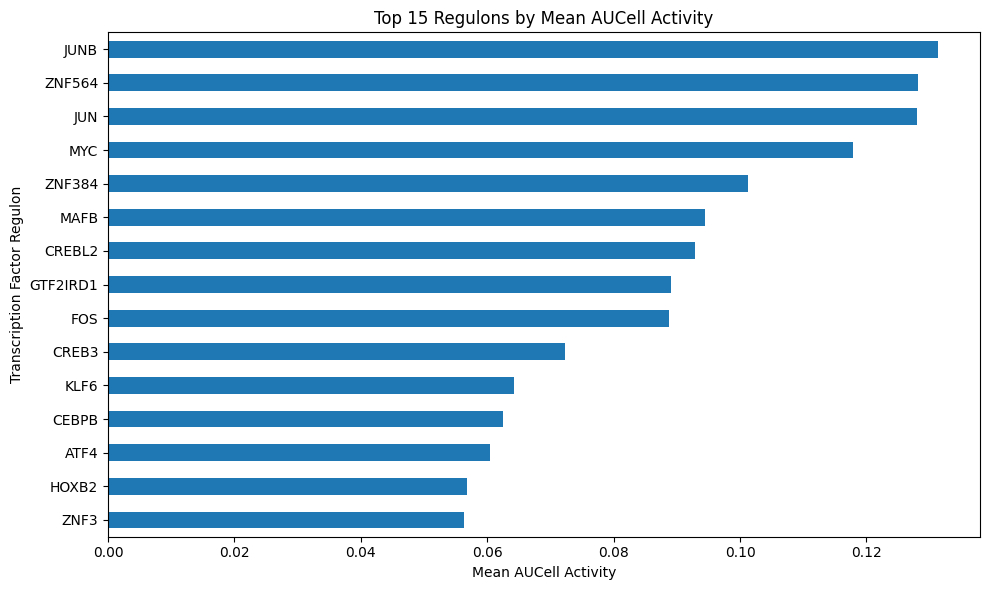

In [30]:
import matplotlib.pyplot as plt

mean_activity = auc_matrix.mean(axis=0).sort_values(
    ascending=False
)

top15 = mean_activity.head(15)

plt.figure(figsize=(10, 6))
top15.sort_values().plot(kind="barh")

plt.xlabel("Mean AUCell Activity")
plt.ylabel("Transcription Factor Regulon")
plt.title("Top 15 Regulons by Mean AUCell Activity")

plt.tight_layout()

figure_dir = RESULT_DIR / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "top15_regulons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
from pathlib import Path

for folder in [
    RESULT_DIR / "networks",
    RESULT_DIR / "regulons",
    RESULT_DIR / "figures"
]:
    folder.mkdir(parents=True, exist_ok=True)

print("All result folders created!")

All result folders created!


In [33]:
# Save AUCell scores
auc_matrix.to_csv(
    RESULT_DIR / "regulons" / "pbmc3k_aucell_final.csv"
)

# Save motif enrichment results
regulons_flat.to_csv(
    RESULT_DIR / "regulons" / "pbmc3k_motif_results.csv",
    index=False
)

# Save GRNBoost2 network
adjacencies = pd.read_csv(ADJACENCY_FILE)

adjacencies.to_csv(
    RESULT_DIR / "networks" / "pbmc3k_adjacencies_final.csv",
    index=False
)

print("All final analysis files saved successfully!")

All final analysis files saved successfully!


In [34]:
for folder in [
    RESULT_DIR / "networks",
    RESULT_DIR / "regulons"
]:
    print(f"\n{folder.name}:")
    for file in folder.iterdir():
        print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")


networks:
pbmc3k_adjacencies_final.csv 31.84 MB

regulons:
ctx_log.txt 0.51 MB
regulons.csv 13.21 MB
regulons_cleaned.csv 13.21 MB
pbmc3k_regulons.gmt 0.19 MB
pbmc3k_aucell.csv 10.03 MB
pbmc3k_aucell_final.csv 9.32 MB
pbmc3k_motif_results.csv 13.21 MB


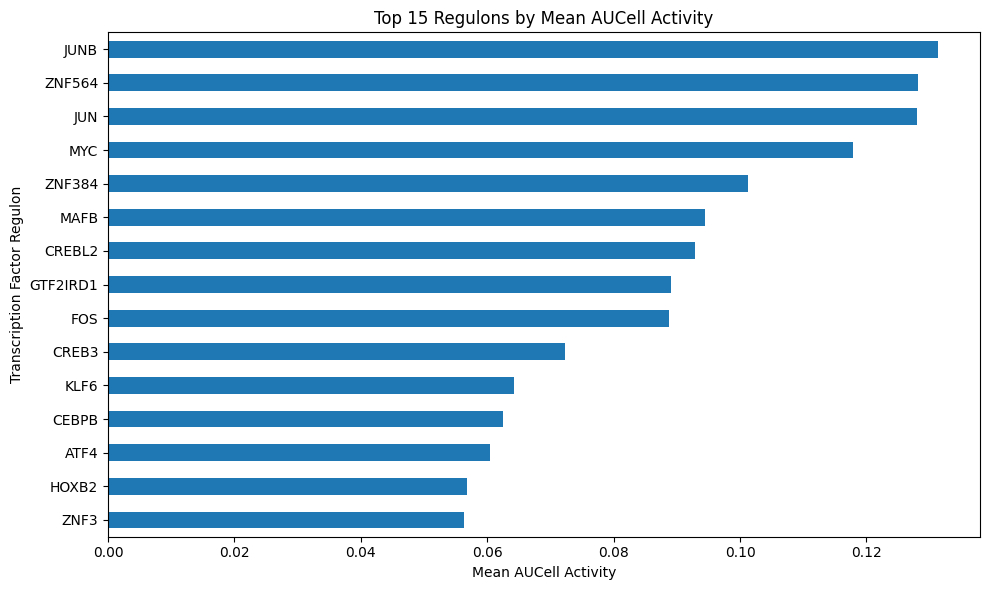

In [36]:
import matplotlib.pyplot as plt

mean_activity = auc_matrix.mean(axis=0).sort_values(
    ascending=False
)

top15 = mean_activity.head(15)

plt.figure(figsize=(10, 6))
top15.sort_values().plot(kind="barh")

plt.xlabel("Mean AUCell Activity")
plt.ylabel("Transcription Factor Regulon")
plt.title("Top 15 Regulons by Mean AUCell Activity")

plt.tight_layout()

plt.savefig(
    figure_dir / "top15_regulons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

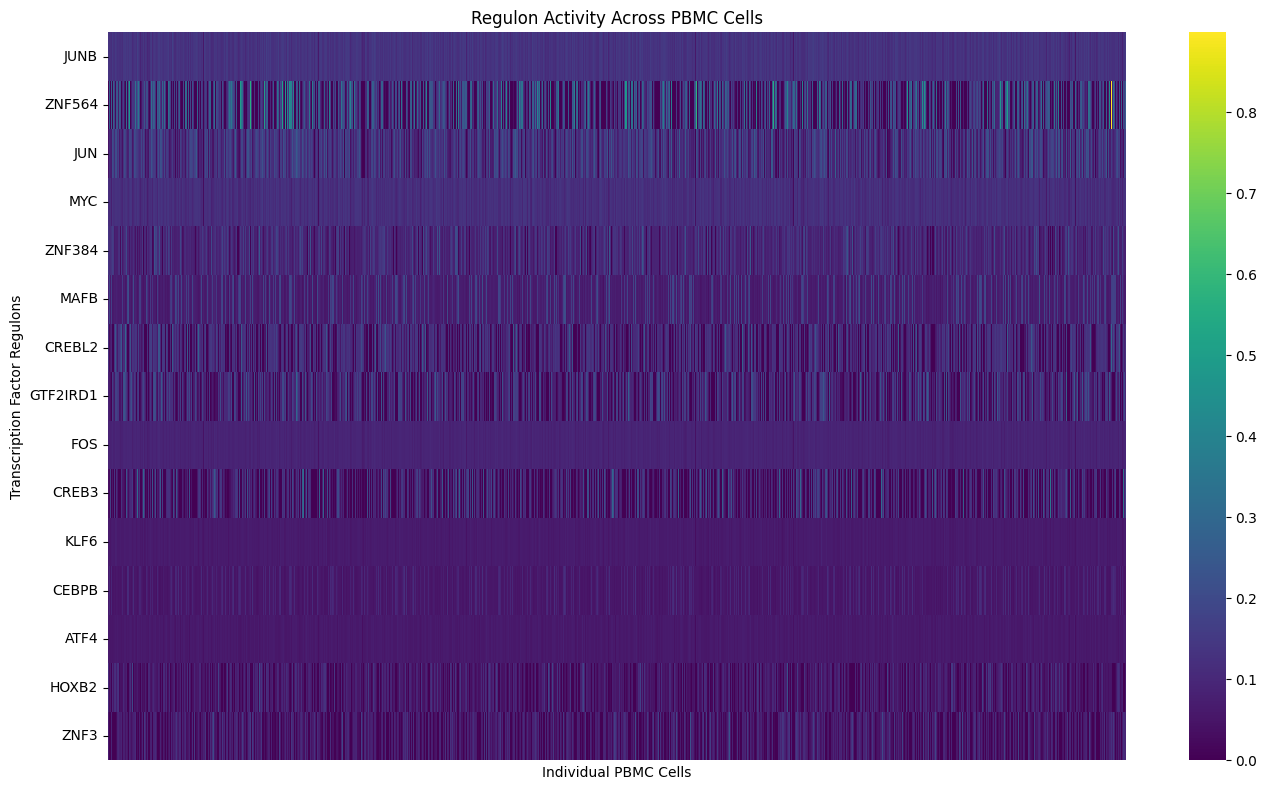

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select the top 15 regulons
top_regulons = mean_activity.head(15).index

# Prepare activity matrix
heatmap_data = auc_matrix[top_regulons]

plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data.T,
    cmap="viridis",
    xticklabels=False,
    yticklabels=True
)

plt.title("Regulon Activity Across PBMC Cells")
plt.xlabel("Individual PBMC Cells")
plt.ylabel("Transcription Factor Regulons")

plt.tight_layout()

plt.savefig(
    figure_dir / "regulon_activity_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
import matplotlib.pyplot as plt
import pandas as pd

# Load GRNBoost2 network
adjacencies = pd.read_csv(ADJACENCY_FILE)

print("Columns:", adjacencies.columns.tolist())
display(adjacencies.head())

Columns: ['TF', 'target', 'importance']


,TF,target,importance
0,SP110,DENND1B,14.565025
1,ZNF574,MPHOSPH6,13.887835
2,CANX,OSTC,11.988640
3,USF2,RFT1,11.712218
4,RPS4X,RPS3,11.701861


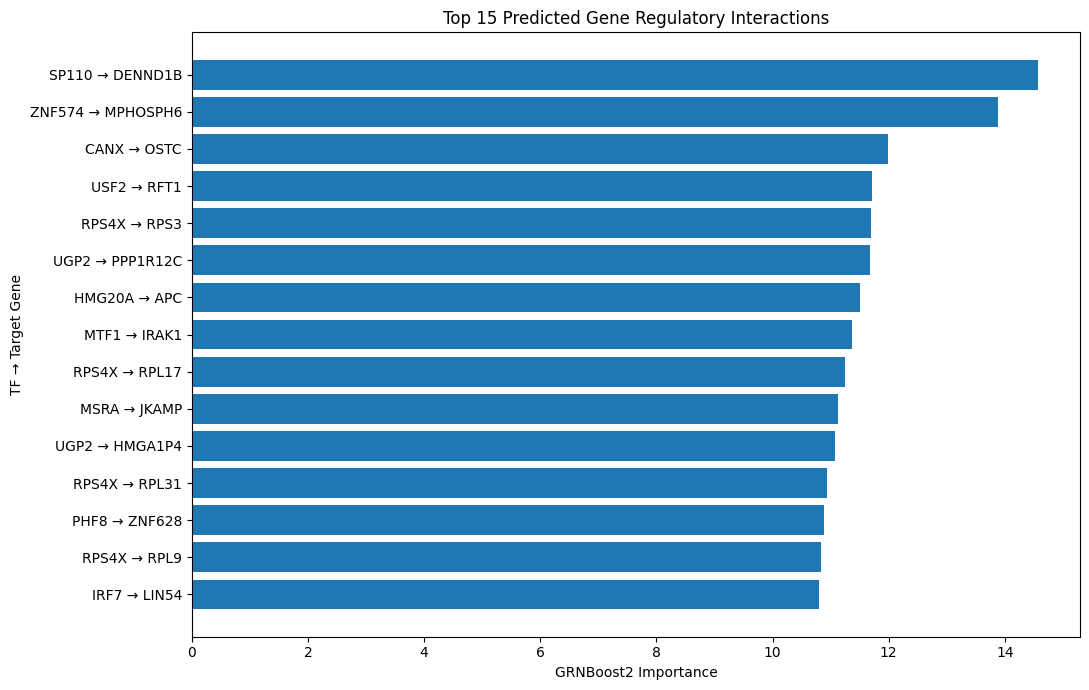

In [39]:
import matplotlib.pyplot as plt

# Select the 15 strongest inferred interactions
top_edges = adjacencies.nlargest(15, "importance").copy()

# Create labels
top_edges["interaction"] = (
    top_edges["TF"] + " → " + top_edges["target"]
)

# Plot
plt.figure(figsize=(11, 7))

plt.barh(
    top_edges["interaction"][::-1],
    top_edges["importance"][::-1]
)

plt.xlabel("GRNBoost2 Importance")
plt.ylabel("TF → Target Gene")
plt.title("Top 15 Predicted Gene Regulatory Interactions")

plt.tight_layout()

plt.savefig(
    figure_dir / "top15_tf_target_interactions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
for filename in [
    "top15_regulons.png",
    "regulon_activity_heatmap.png",
    "top15_tf_target_interactions.png"
]:
    path = figure_dir / filename
    print(filename, "—", "Saved" if path.exists() else "Not found")

top15_regulons.png — Saved
regulon_activity_heatmap.png — Saved
top15_tf_target_interactions.png — Saved


In [41]:
figure_dir.mkdir(parents=True, exist_ok=True)

# Save the figures explicitly
plt.figure()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [42]:
figure_files = [
    "top15_regulons.png",
    "regulon_activity_heatmap.png",
    "top15_tf_target_interactions.png"
]

for filename in figure_files:
    path = figure_dir / filename
    print(
        filename,
        "—",
        f"{path.stat().st_size / 1024:.1f} KB"
        if path.exists() else "MISSING"
    )

top15_regulons.png — 122.3 KB
regulon_activity_heatmap.png — 242.9 KB
top15_tf_target_interactions.png — 174.5 KB
